Atlas Homework

In [1]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

<Axes: >

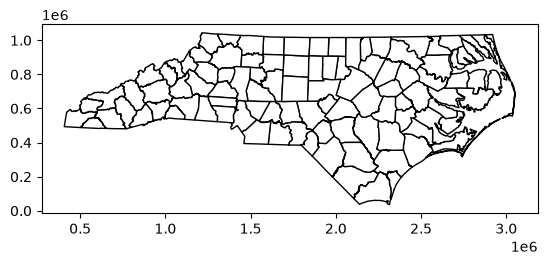

In [2]:
# getting the US census data

url_0 = "https://www2.census.gov/geo/tiger/GENZ2024/shp/" # url for census tiger data 
url_county = "cb_2024_us_county_500k.zip" # county level
url_state = "cb_2024_us_state_500k.zip" # state level 


## Code for county level data 

counties = gpd.read_file(url_0+url_county)
nc_counties = counties.loc[counties["STATEFP"] == "37"].to_crs(6543).copy()
nc_counties.plot(edgecolor="black", facecolor="white")

In [4]:
polls = gpd.read_file("geog592-ejamie/homework/week10/North_Carolina_Voting_Polling_Places.geojson")

In [12]:
polls = polls.to_crs(6543)

In [13]:
polls_nc = gpd.sjoin(polls, nc_counties, predicate="within")

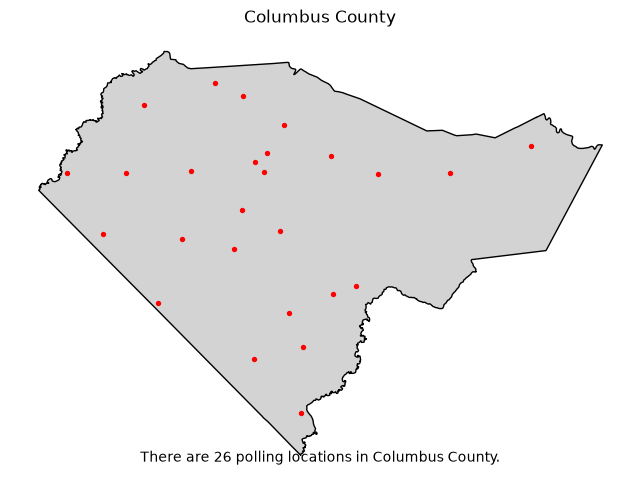

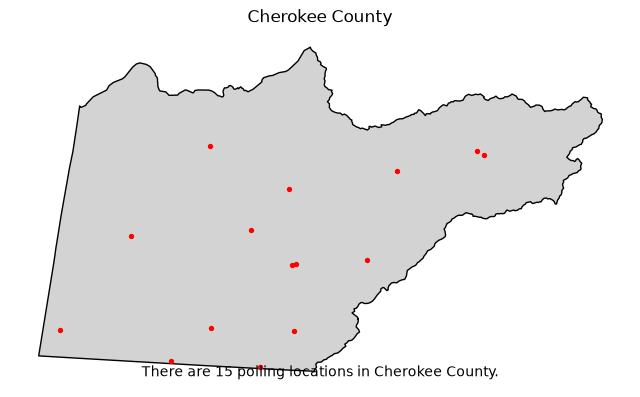

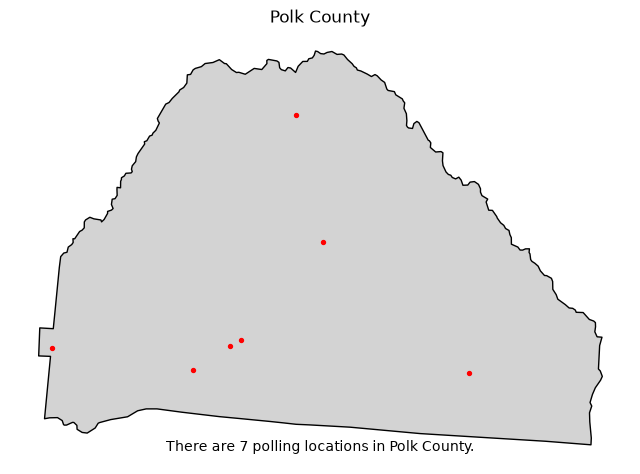

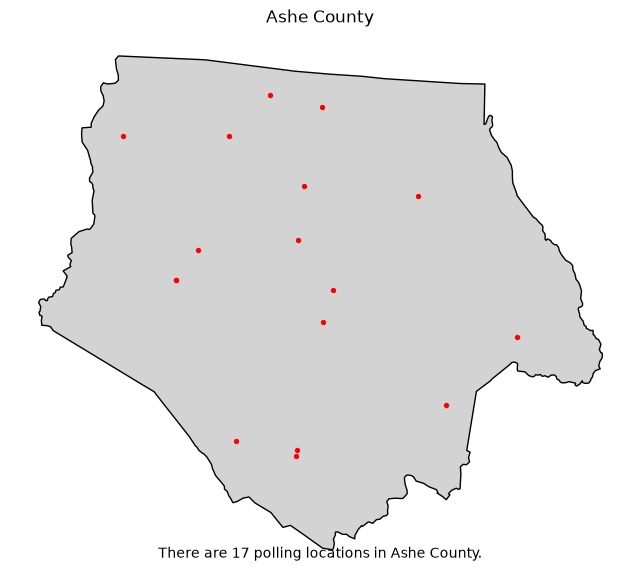

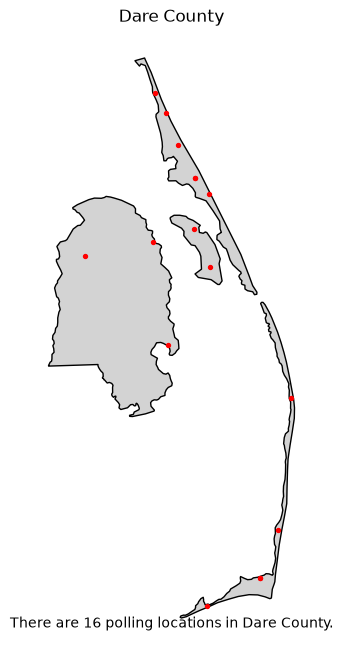

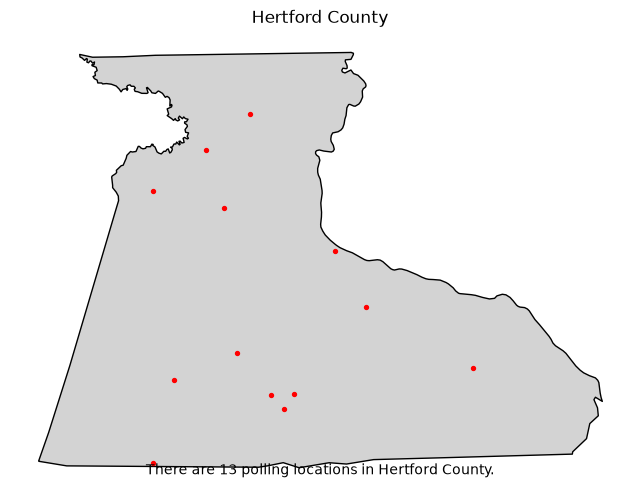

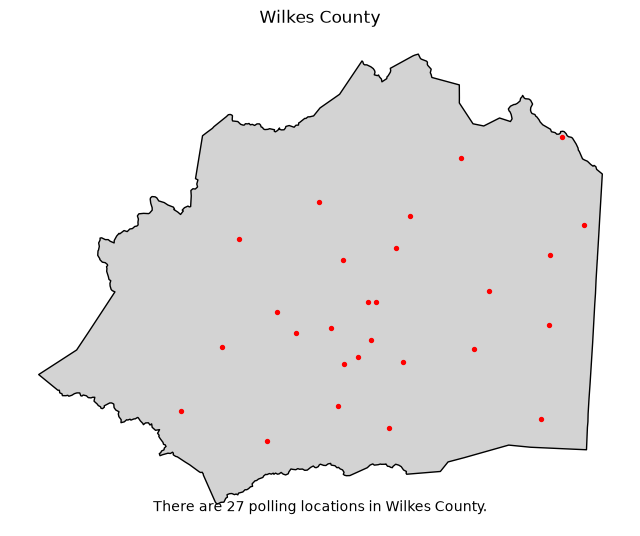

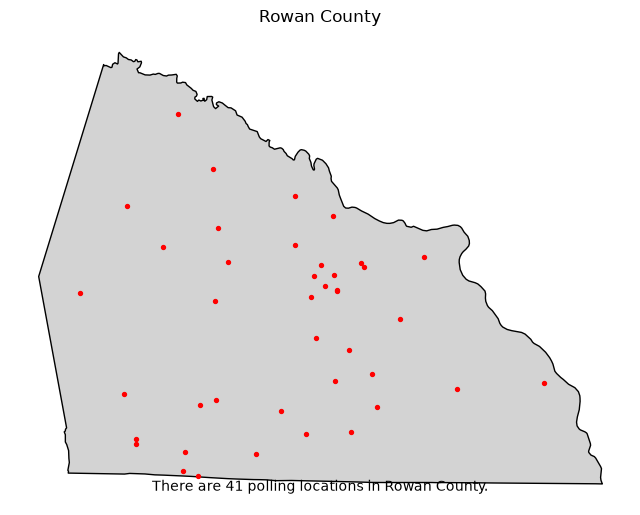

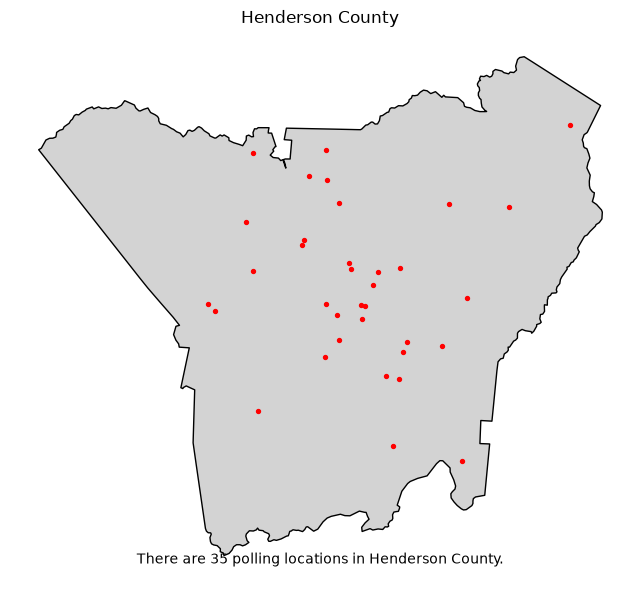

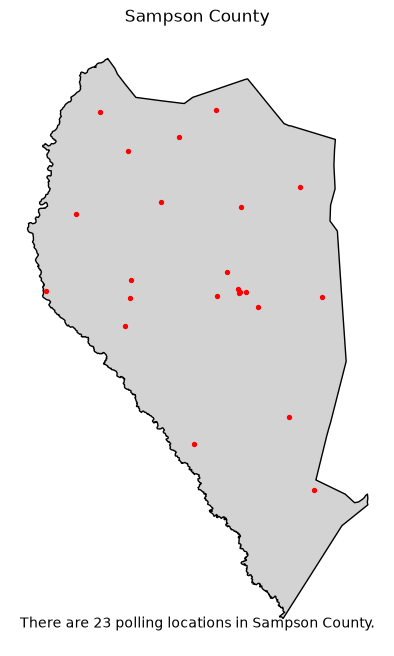

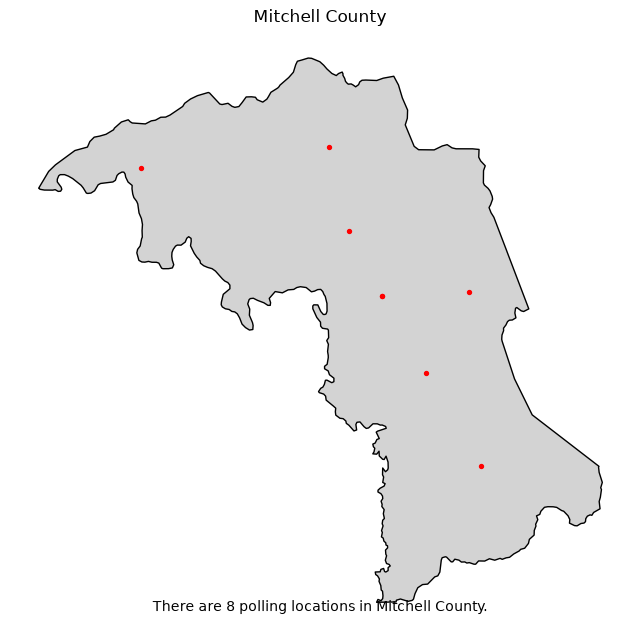

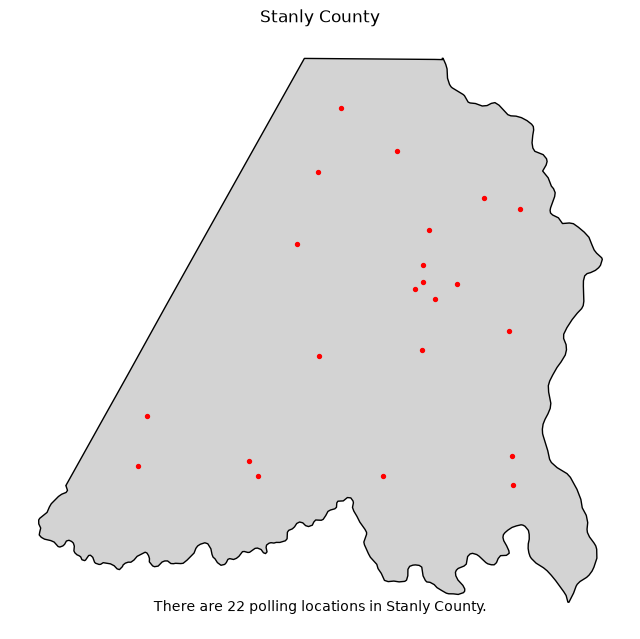

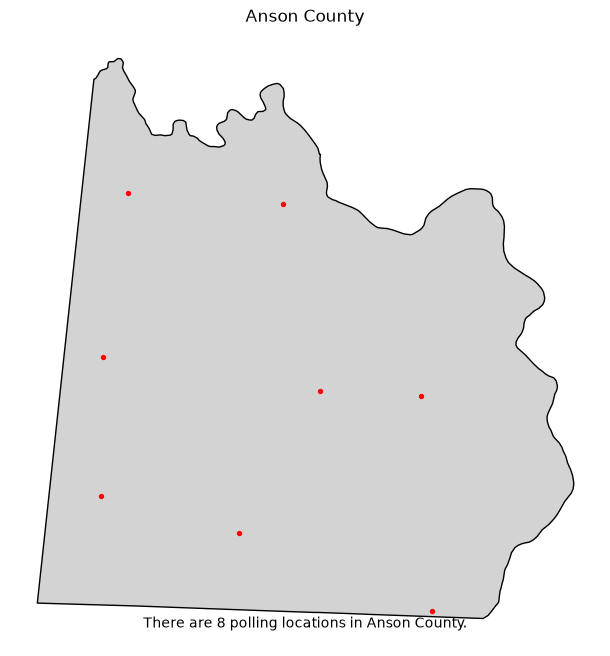

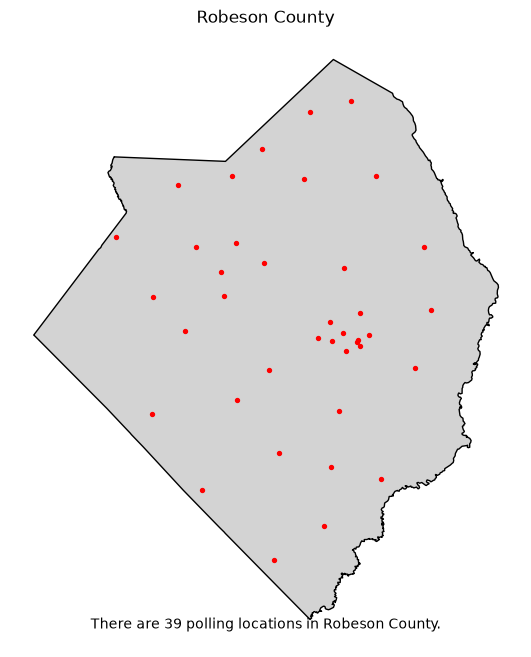

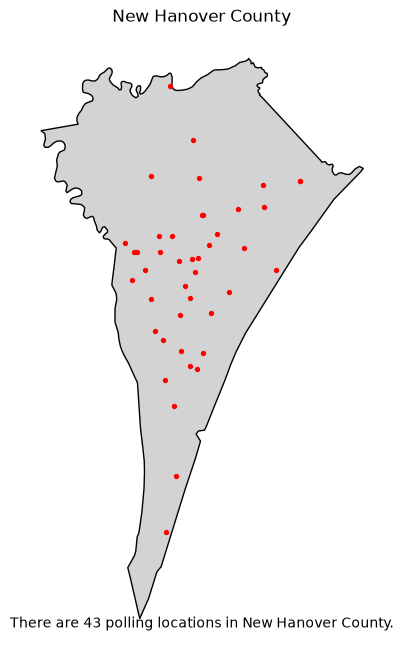

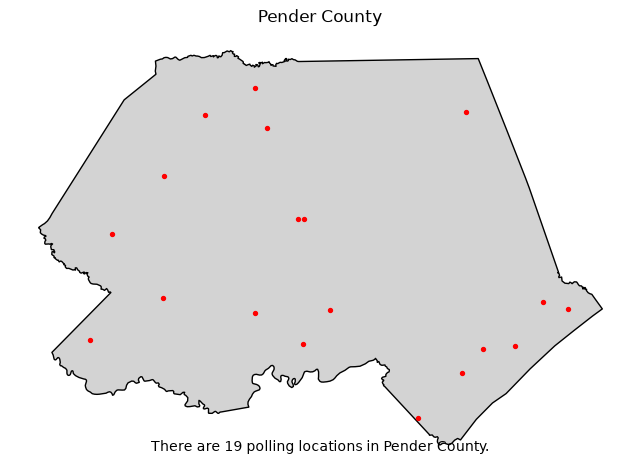

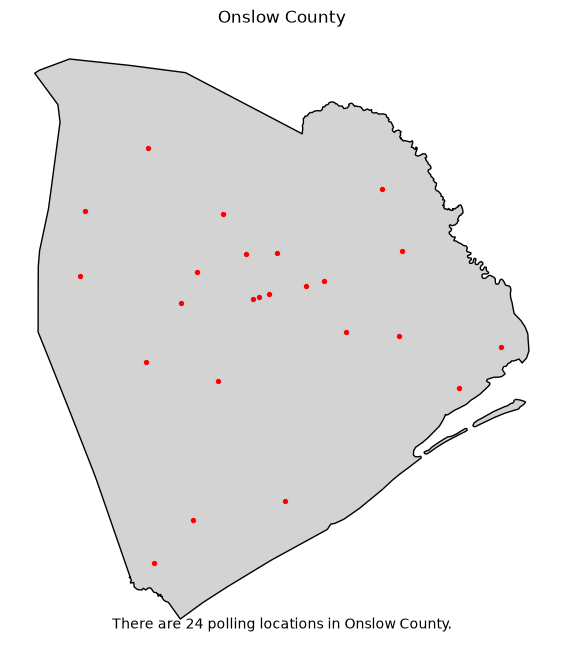

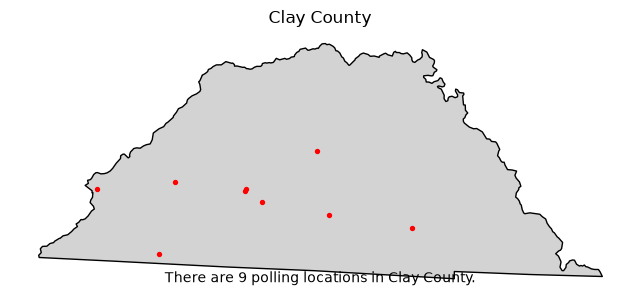

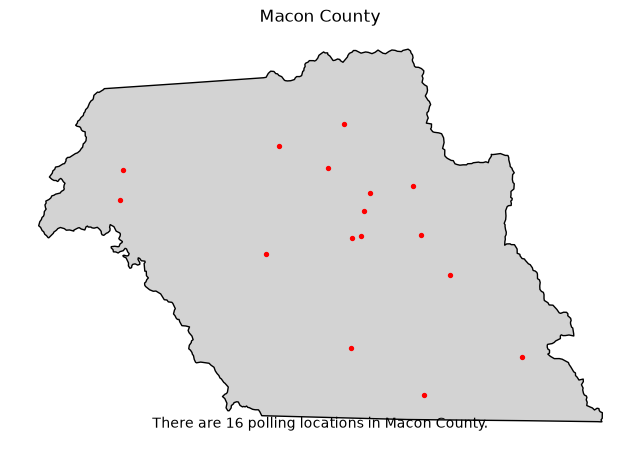

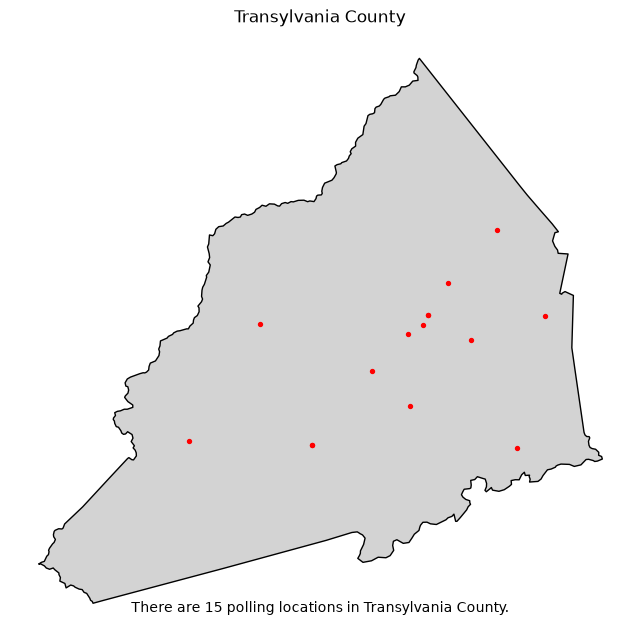

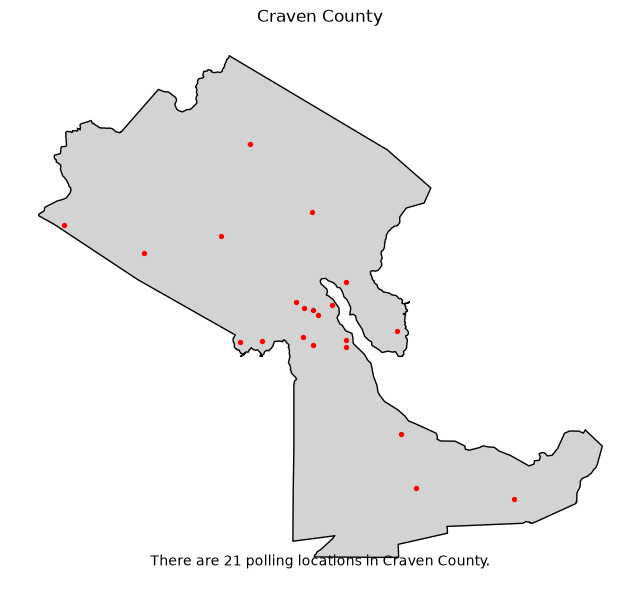

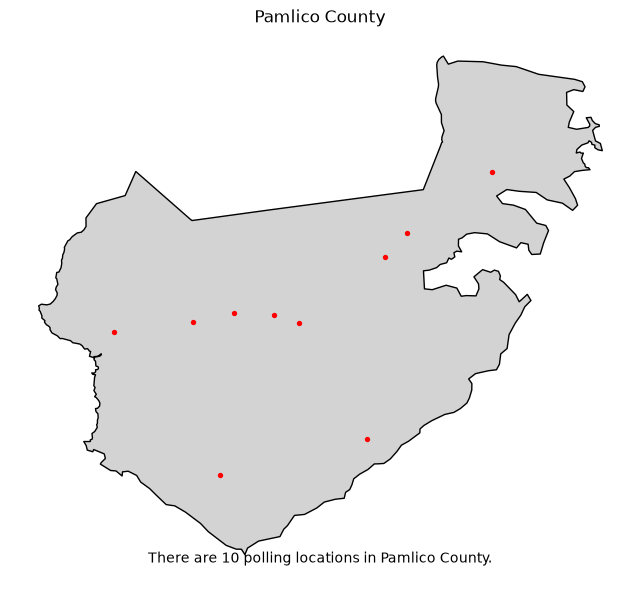

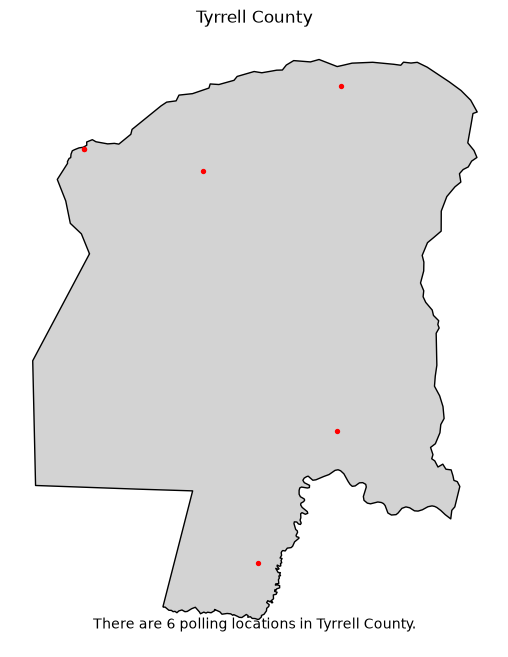

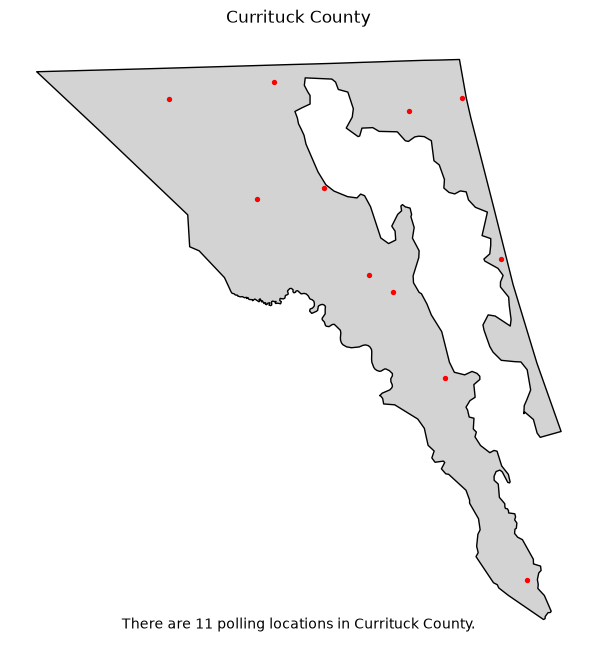

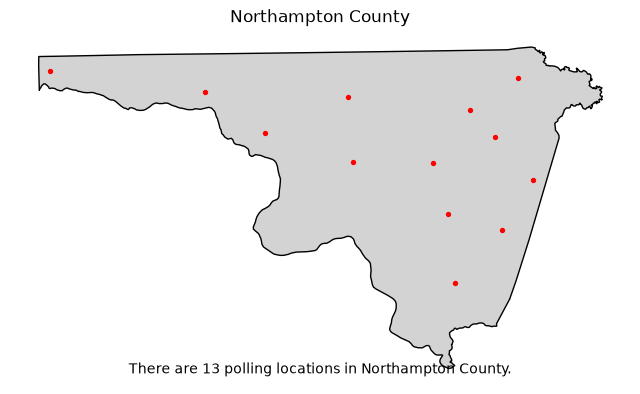

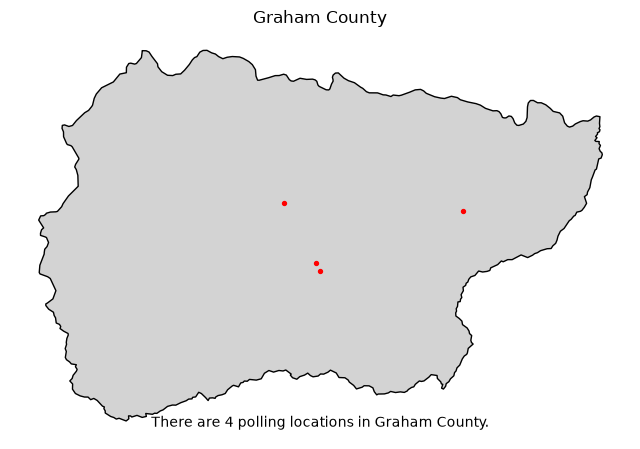

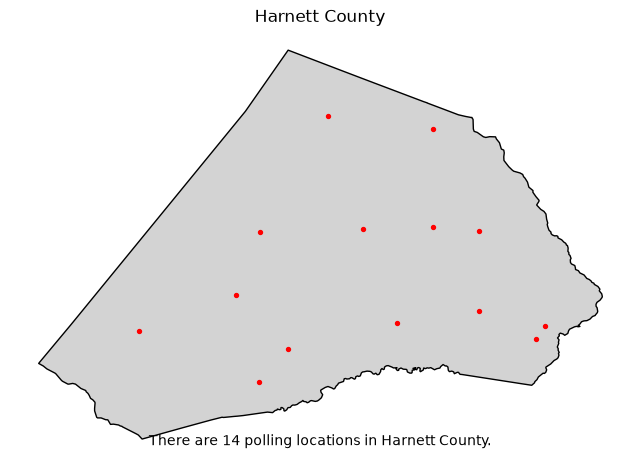

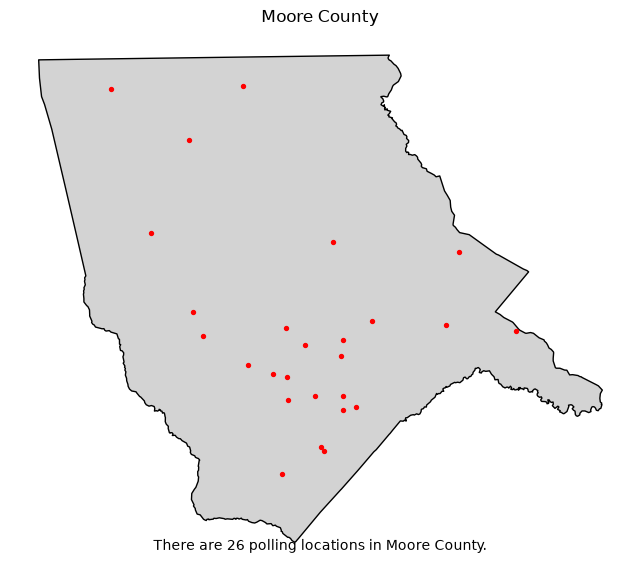

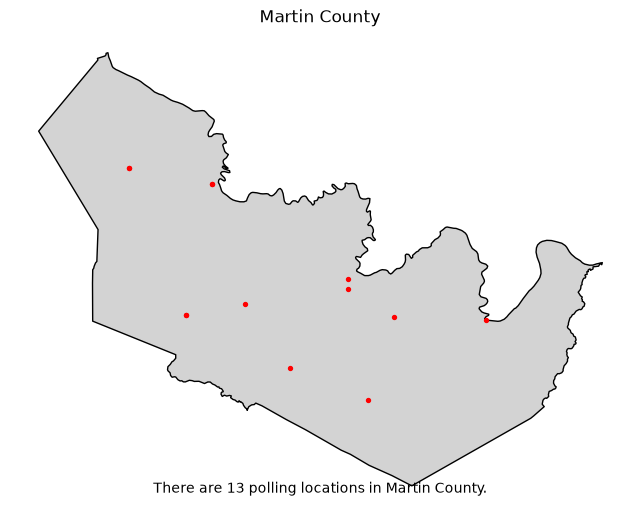

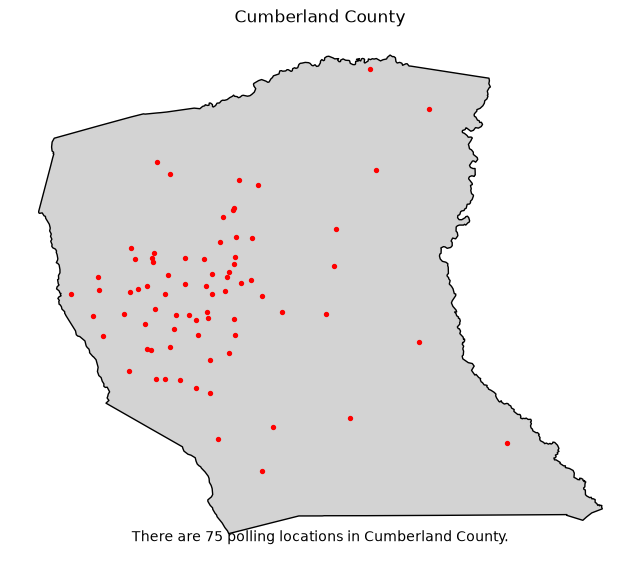

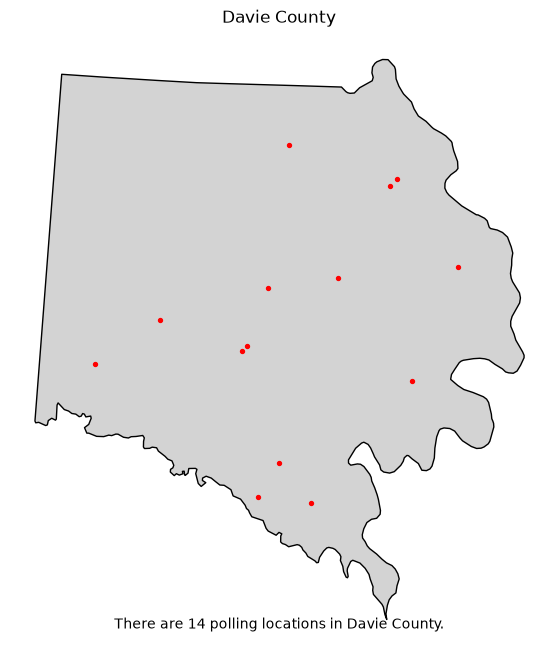

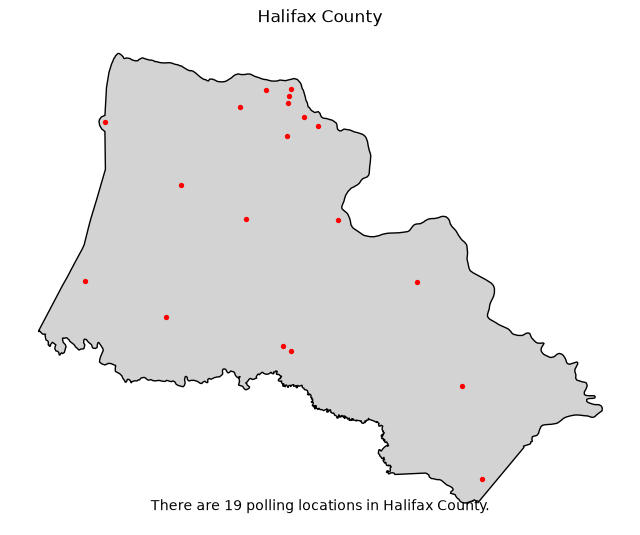

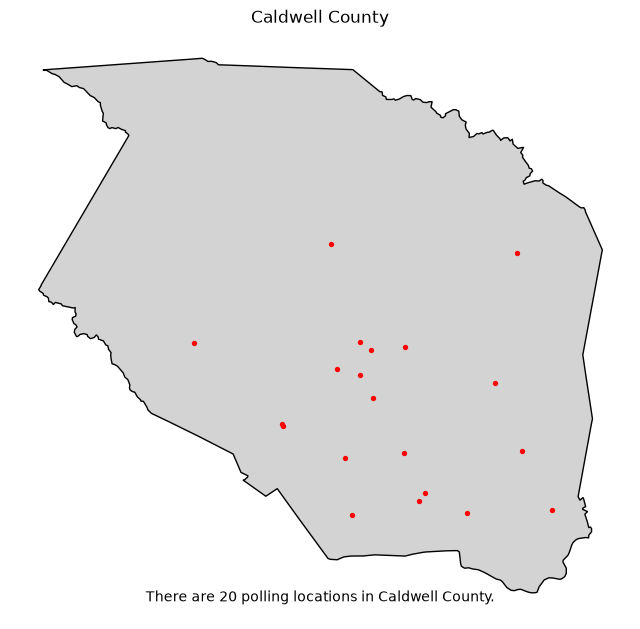

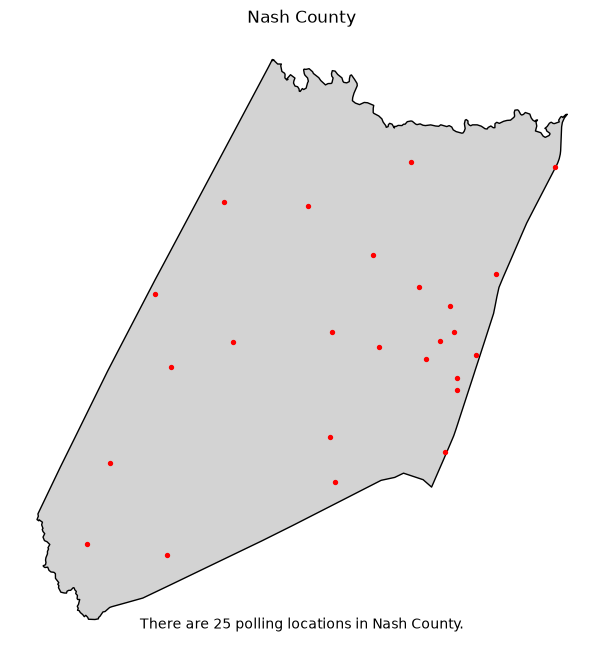

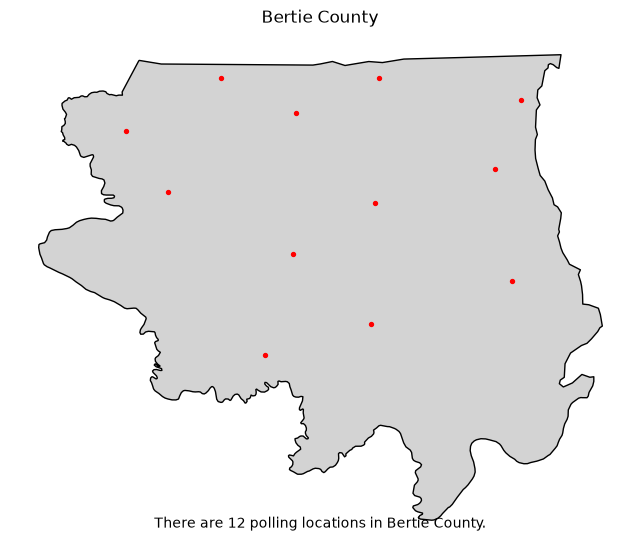

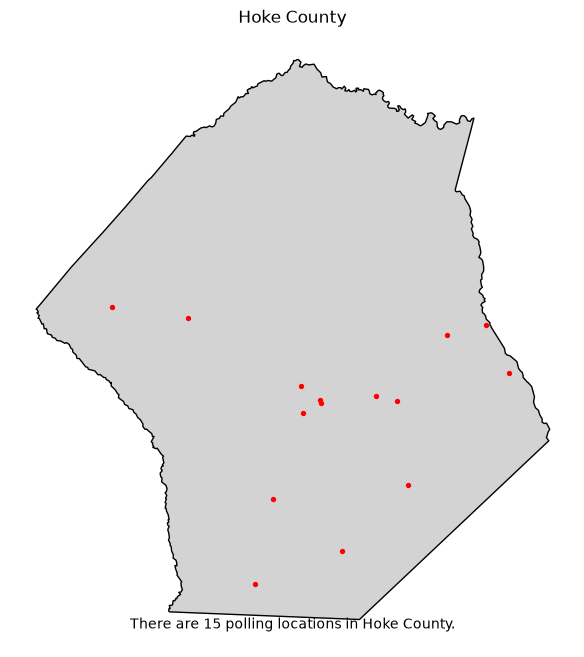

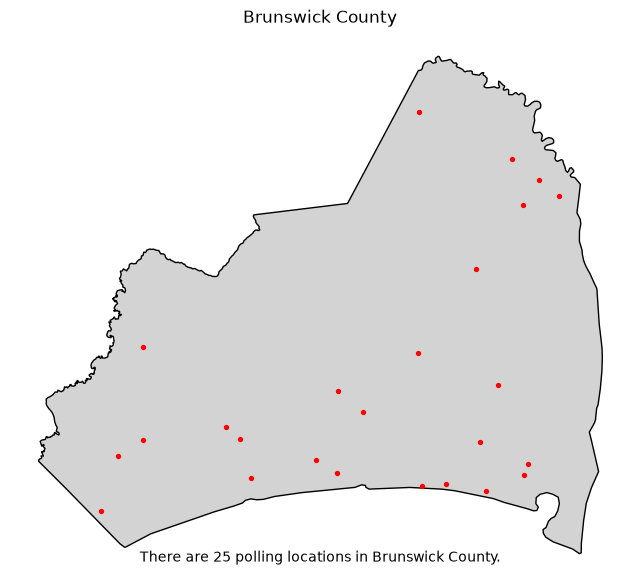

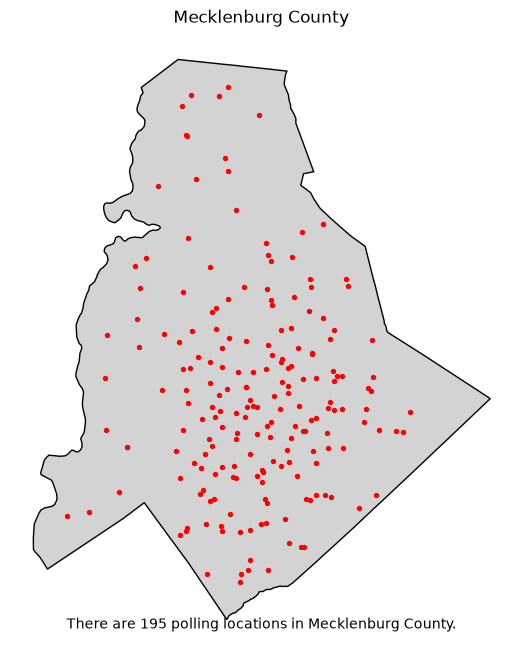

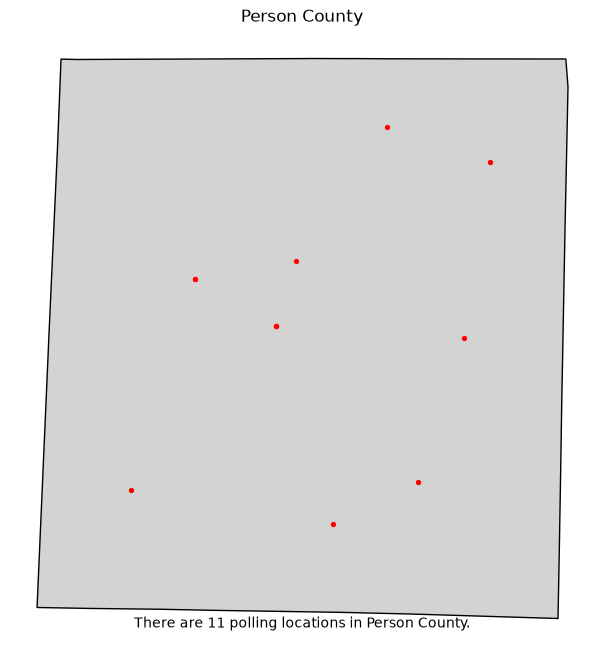

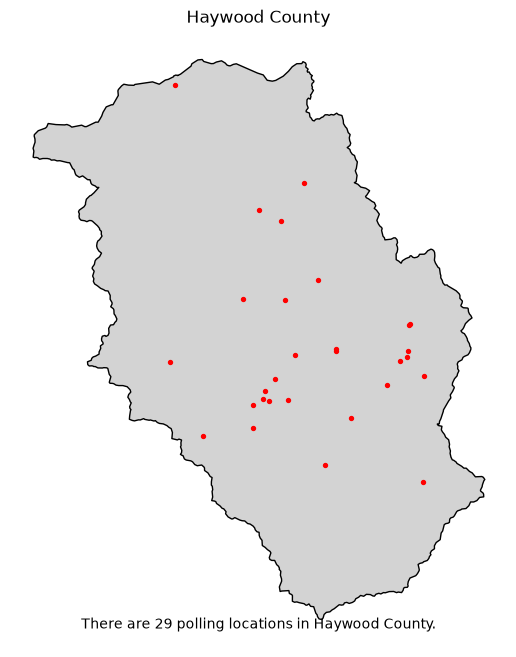

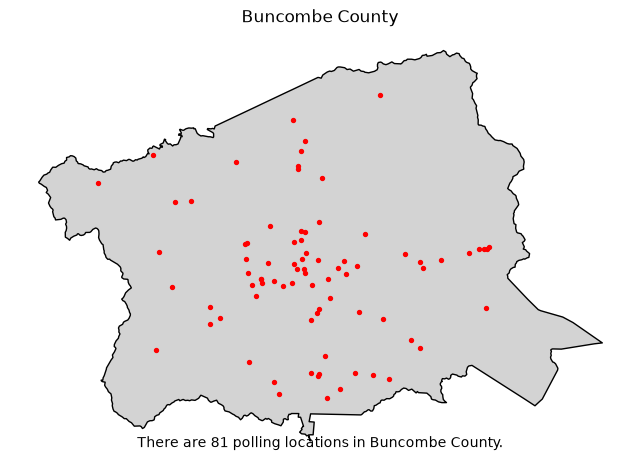

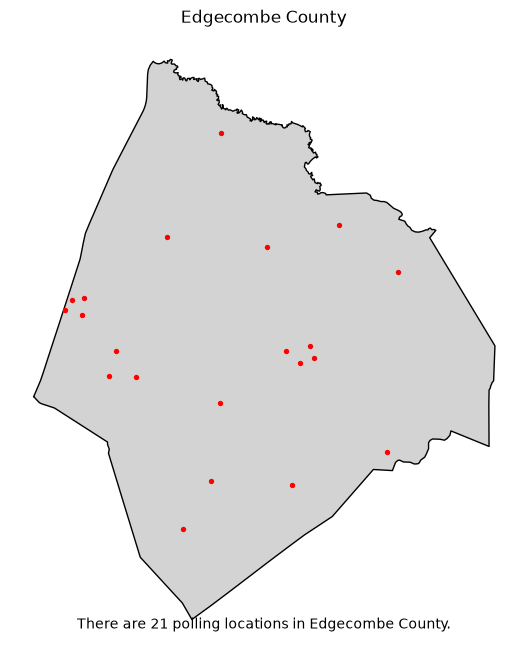

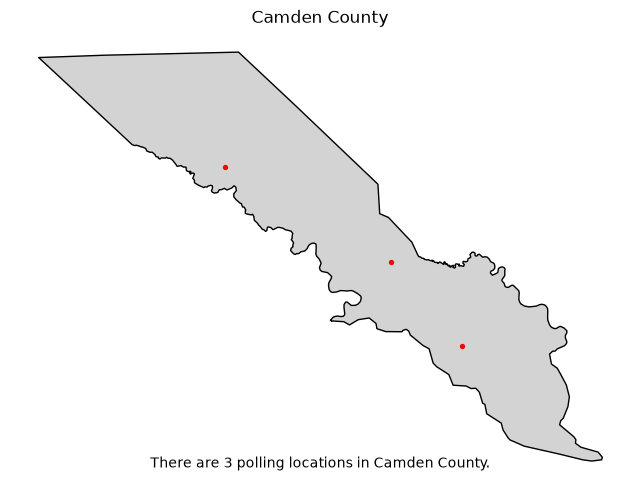

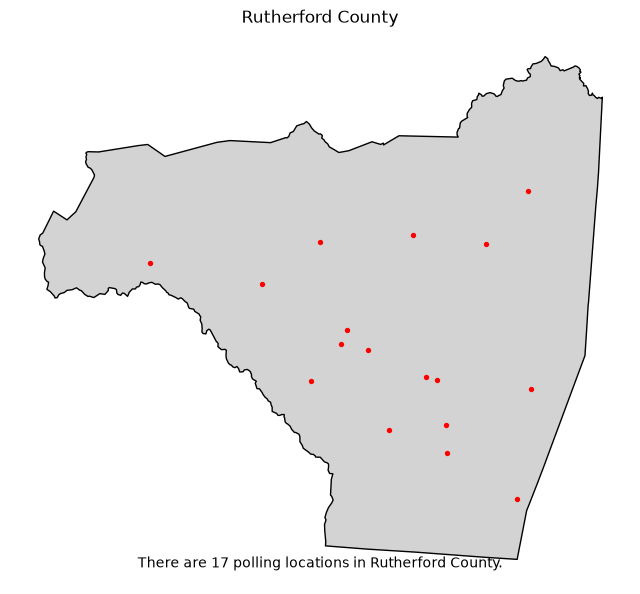

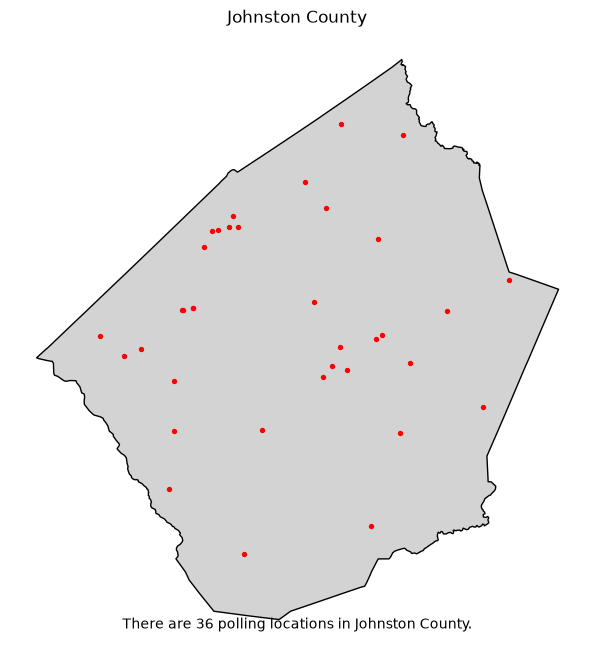

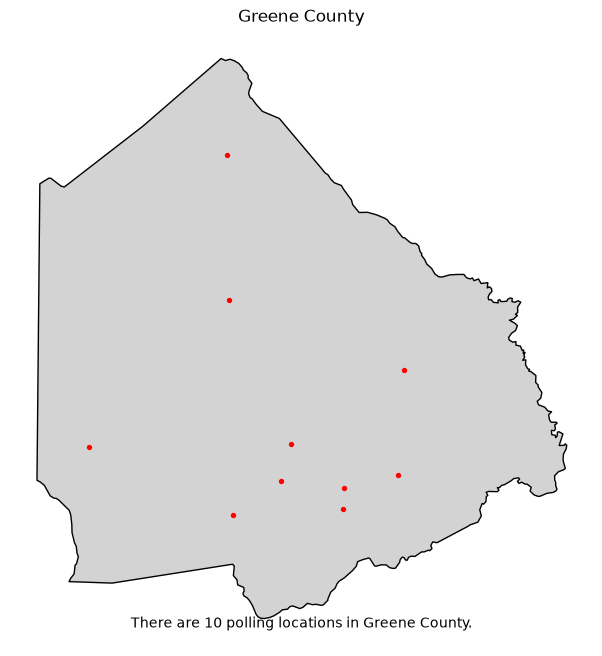

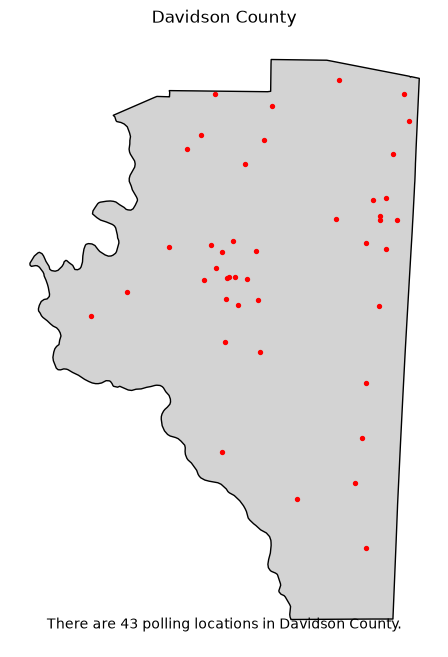

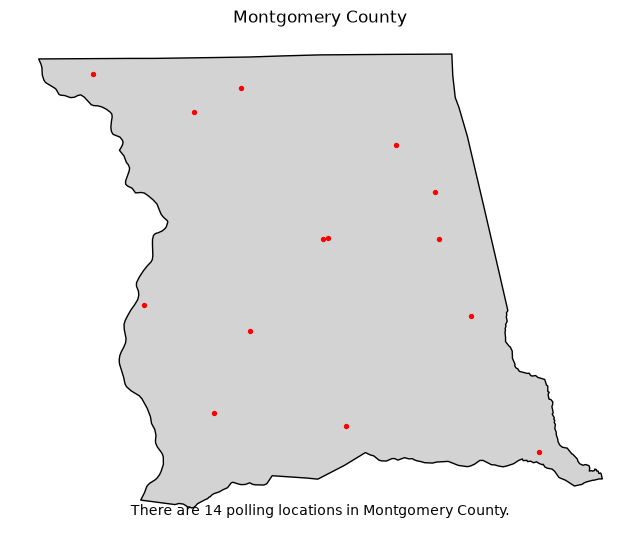

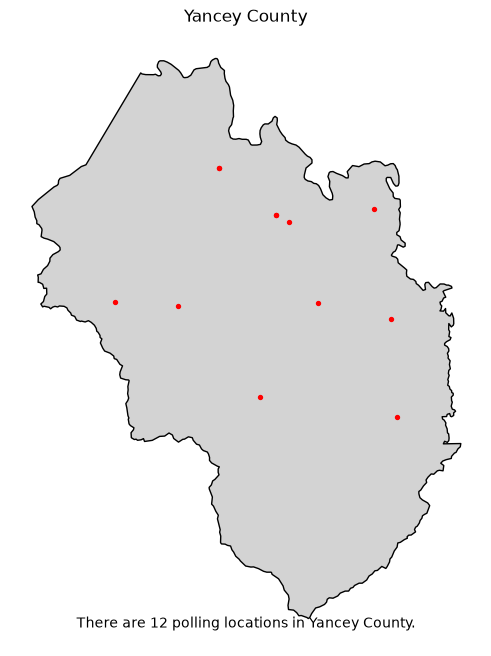

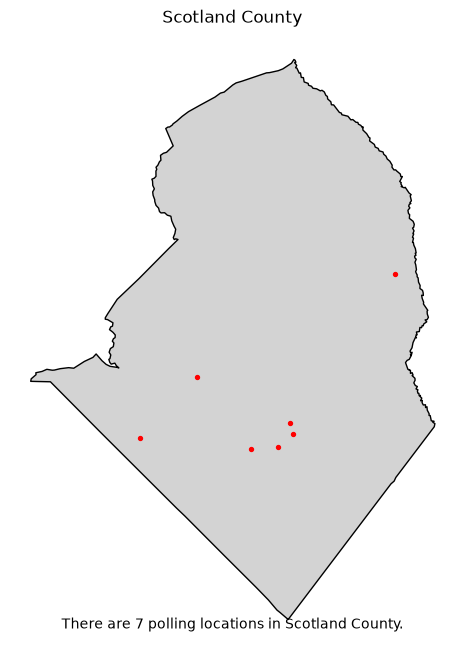

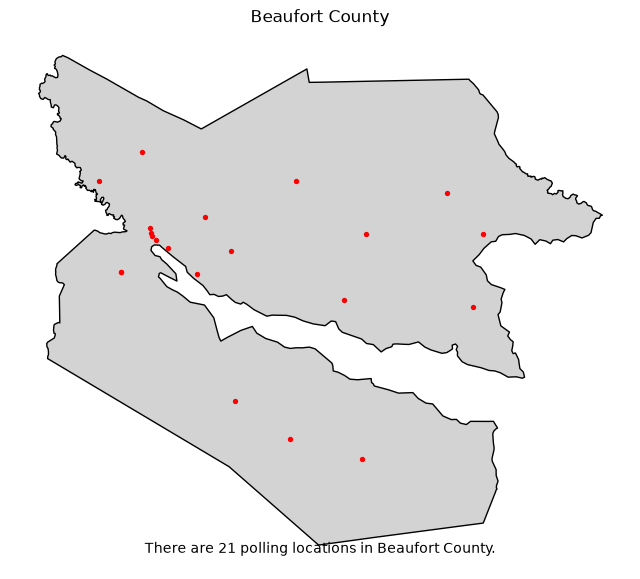

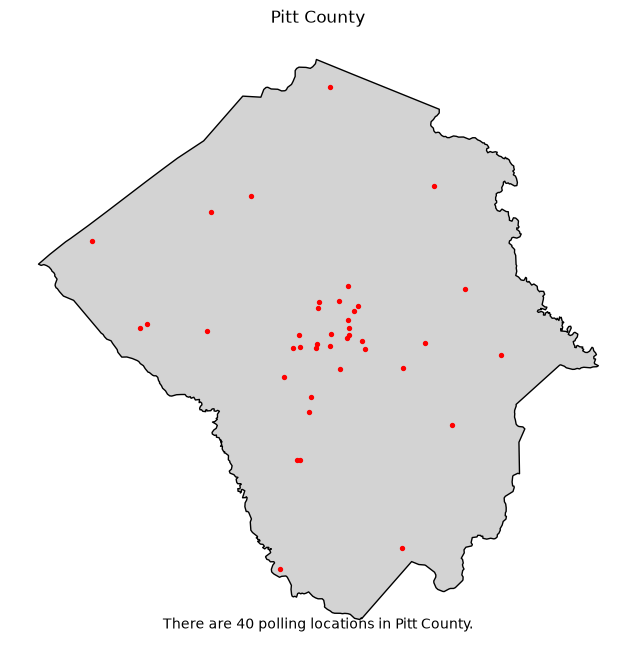

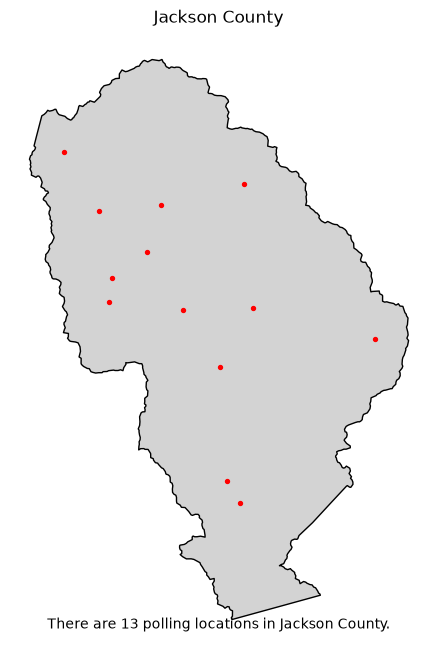

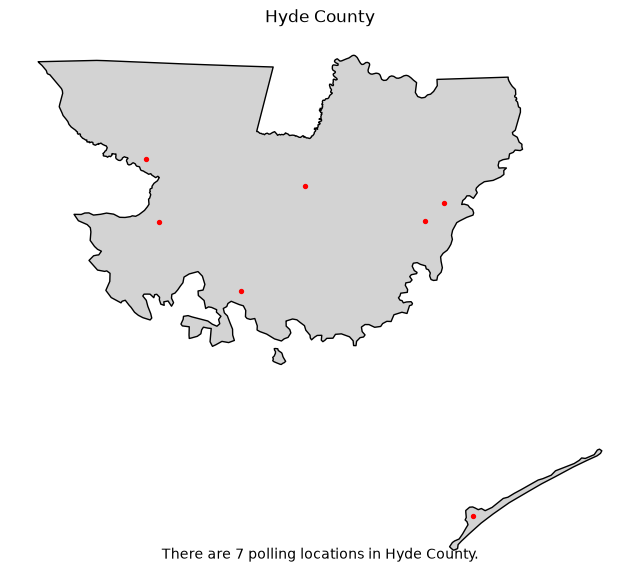

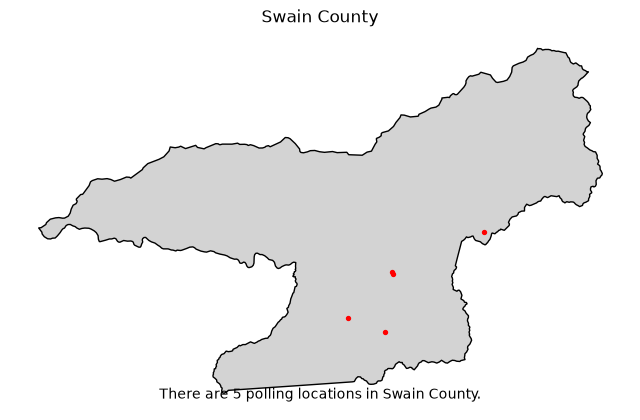

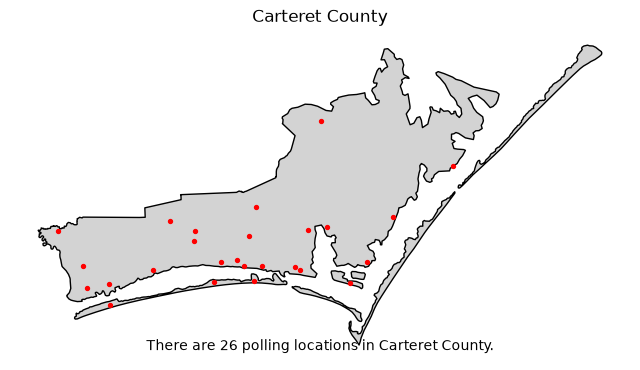

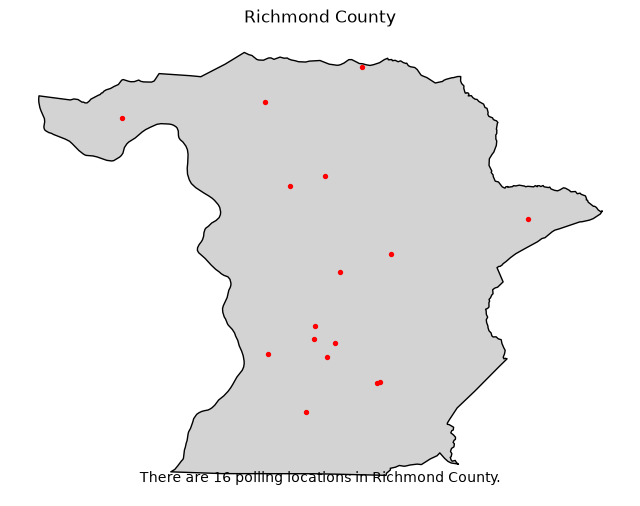

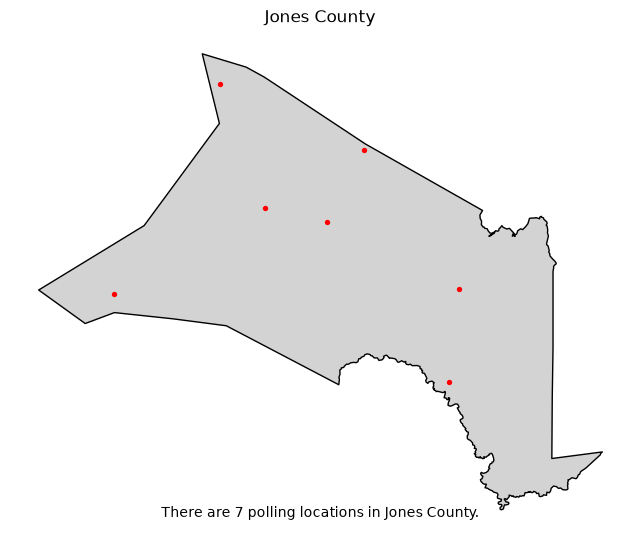

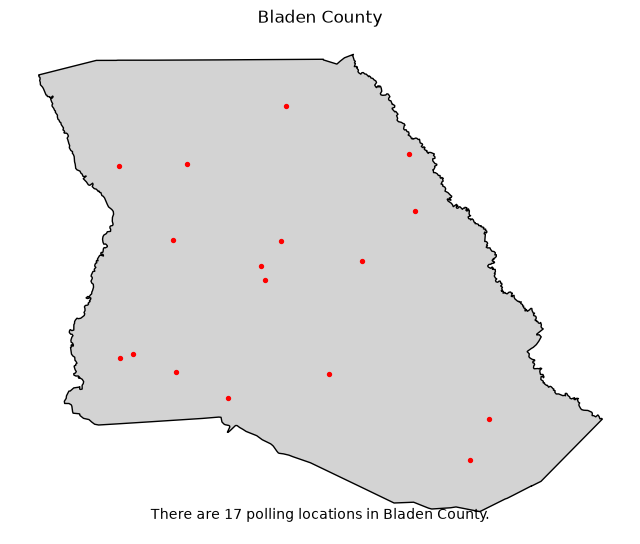

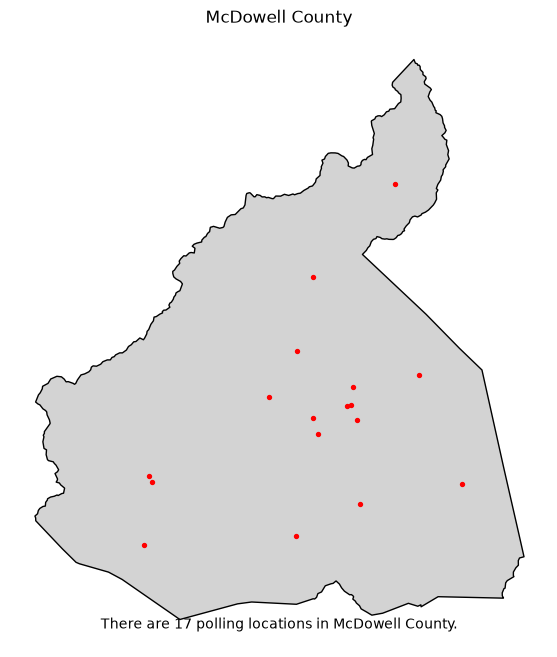

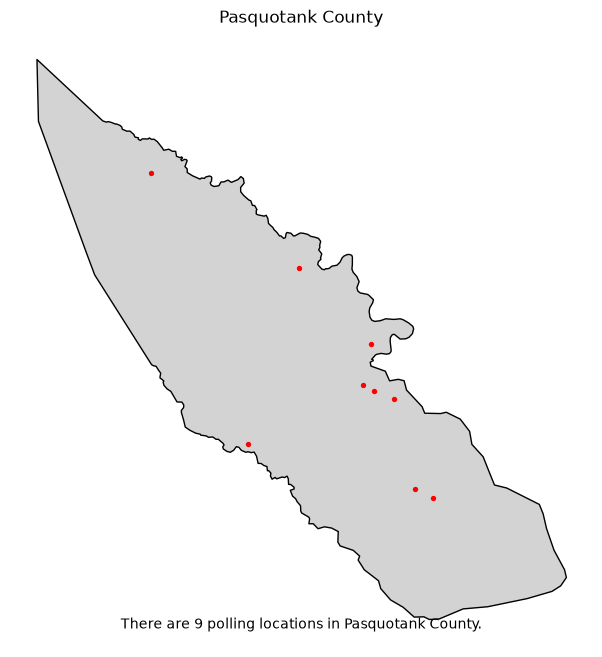

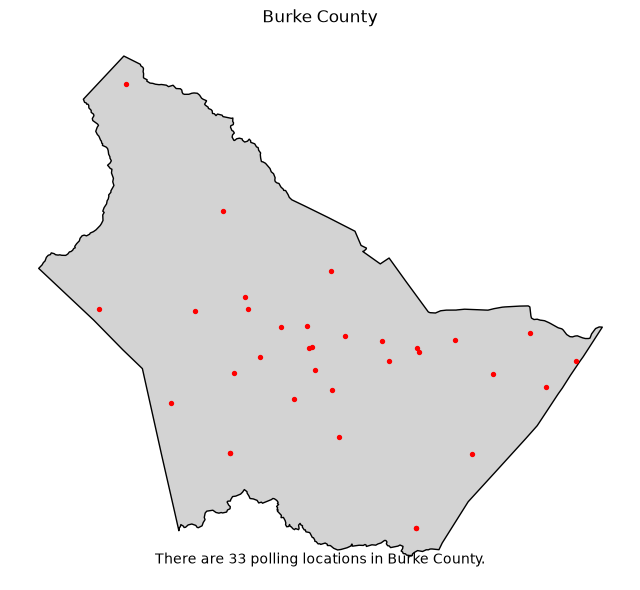

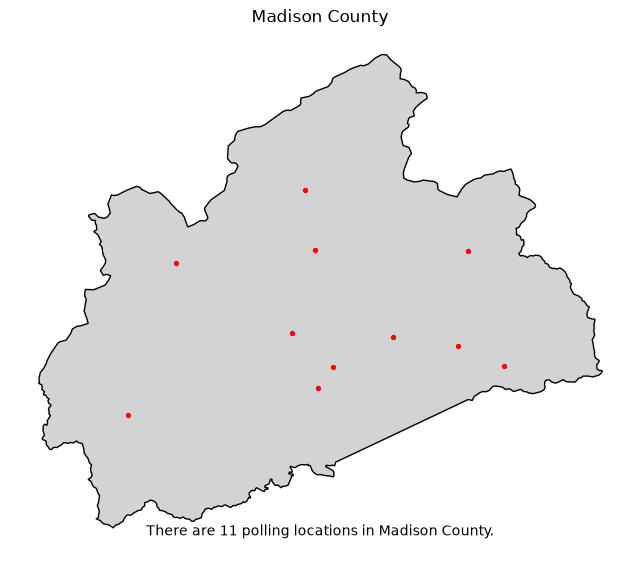

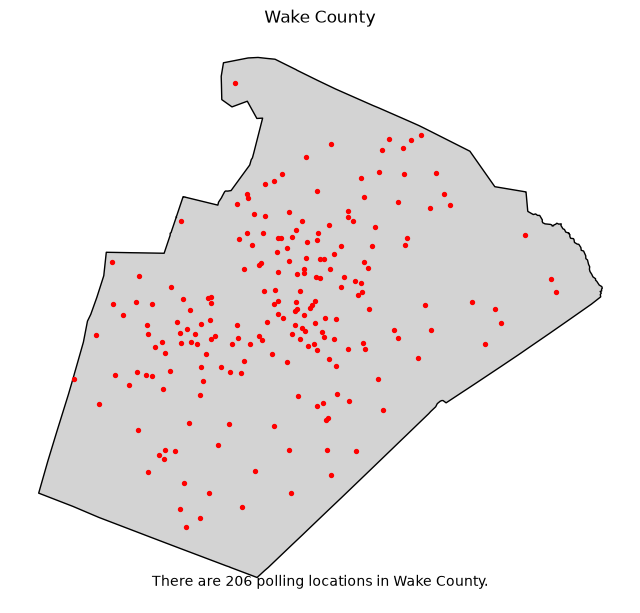

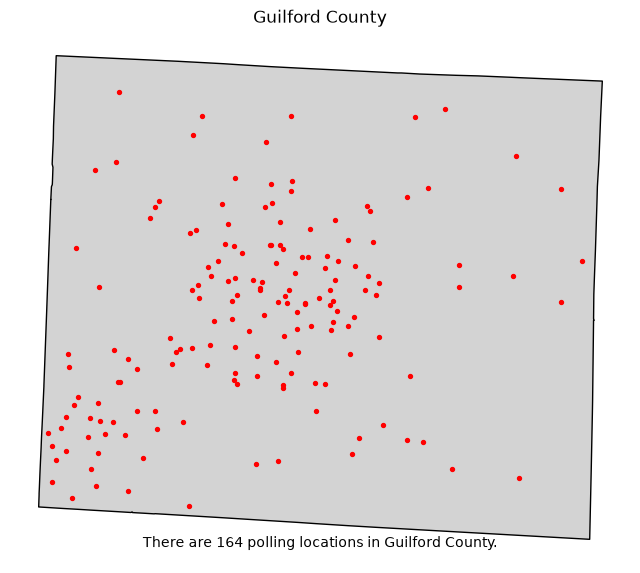

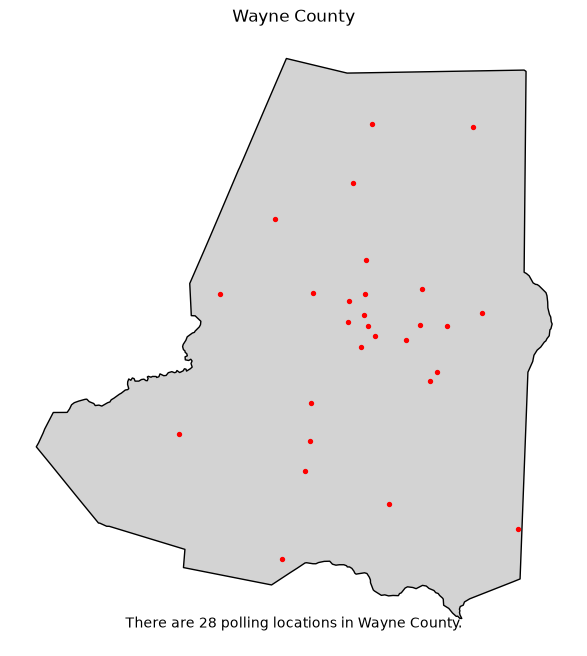

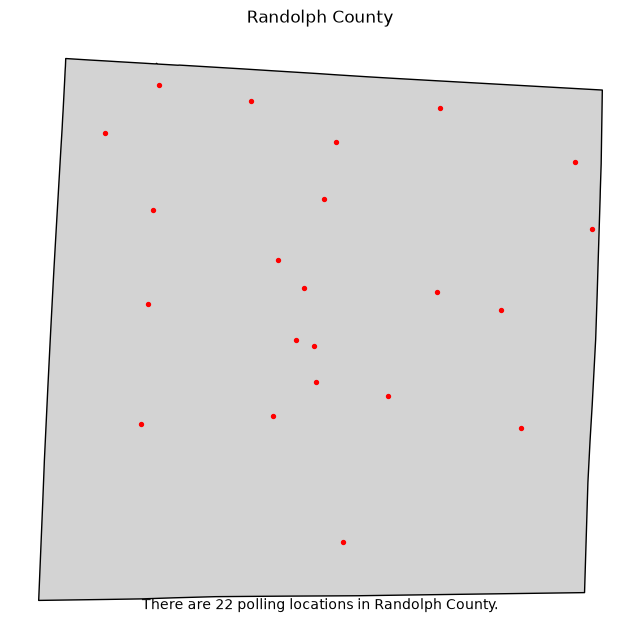

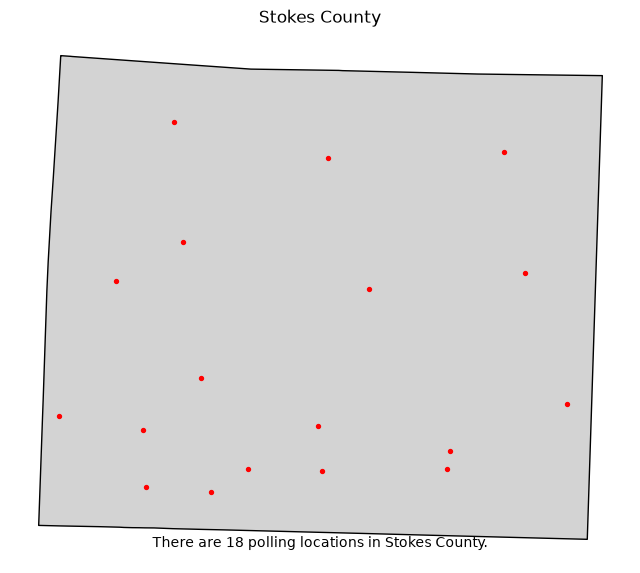

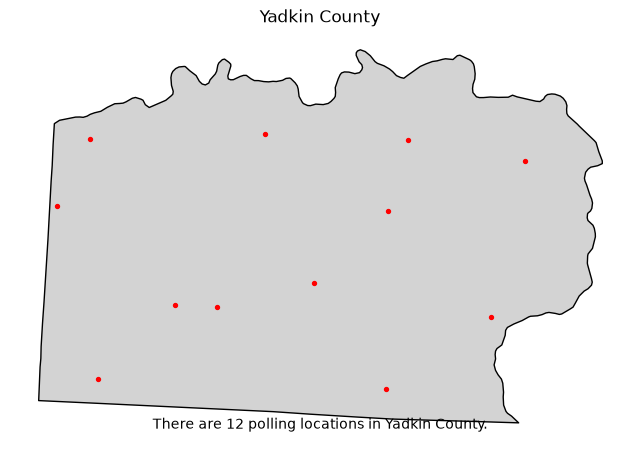

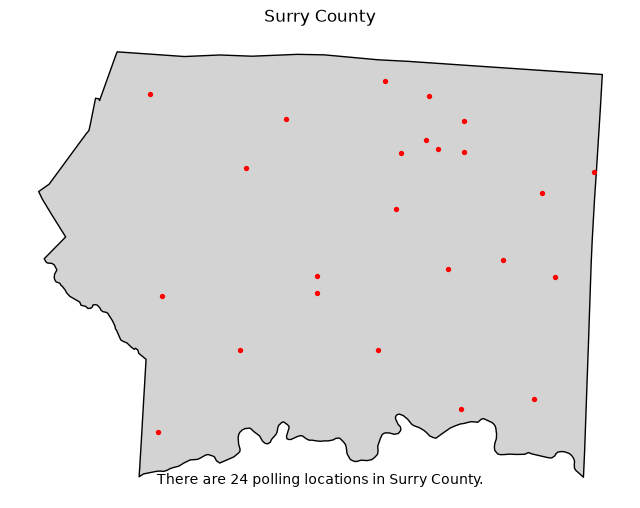

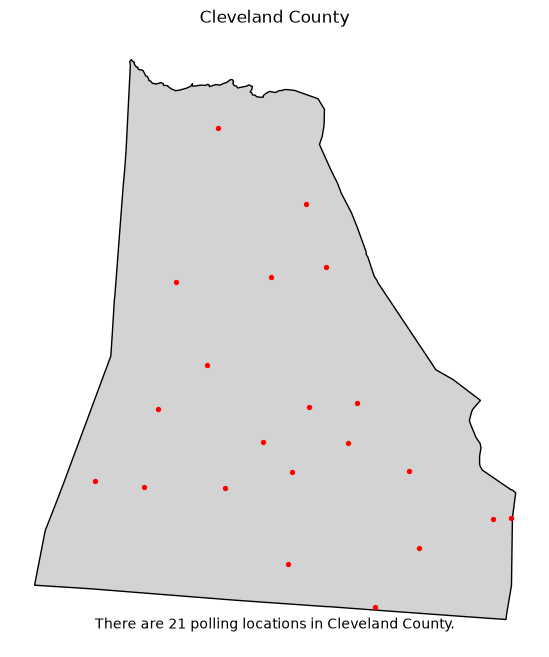

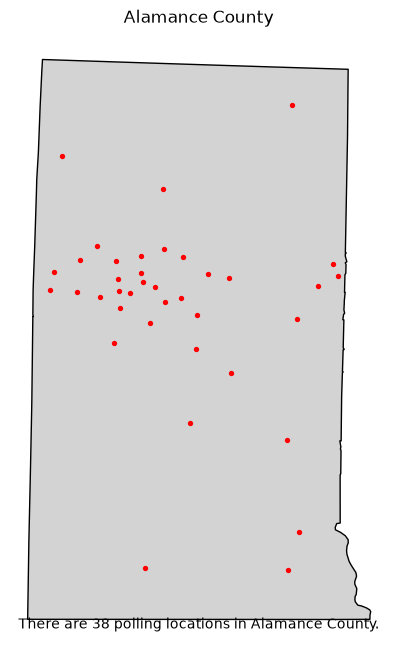

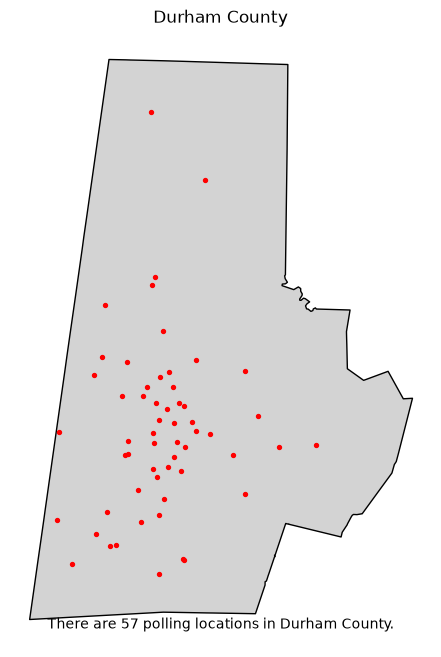

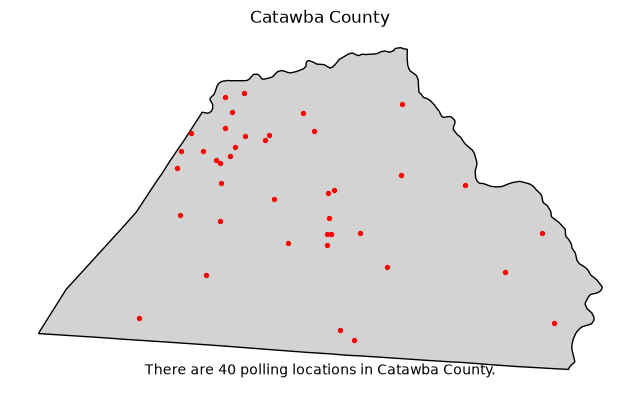

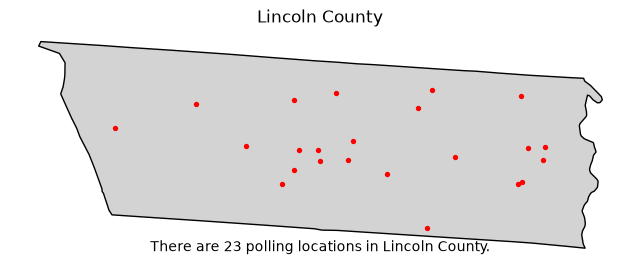

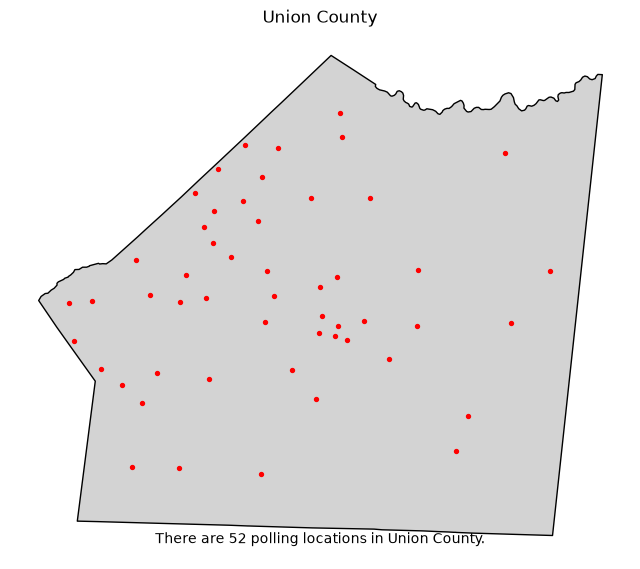

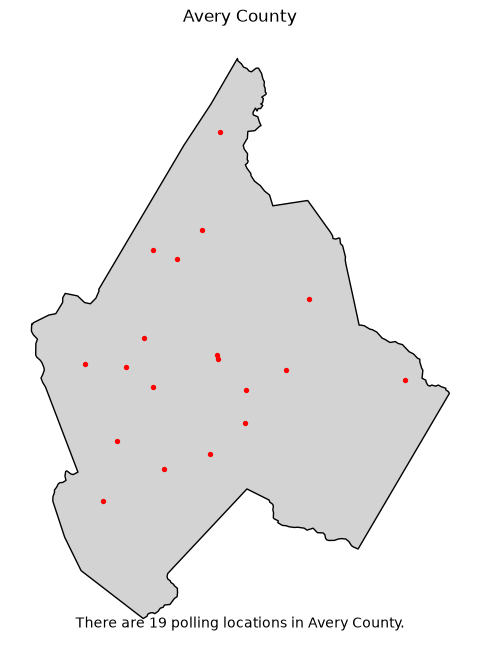

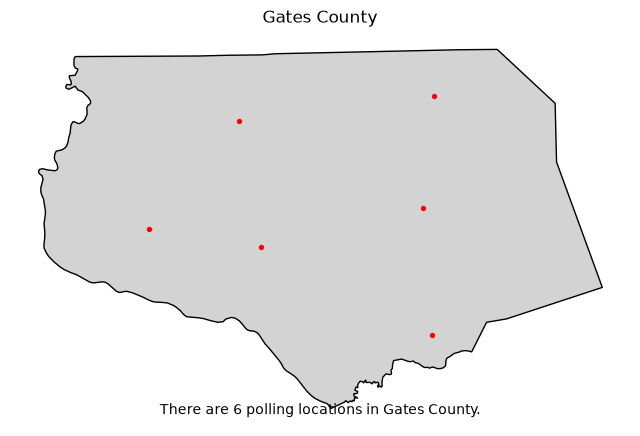

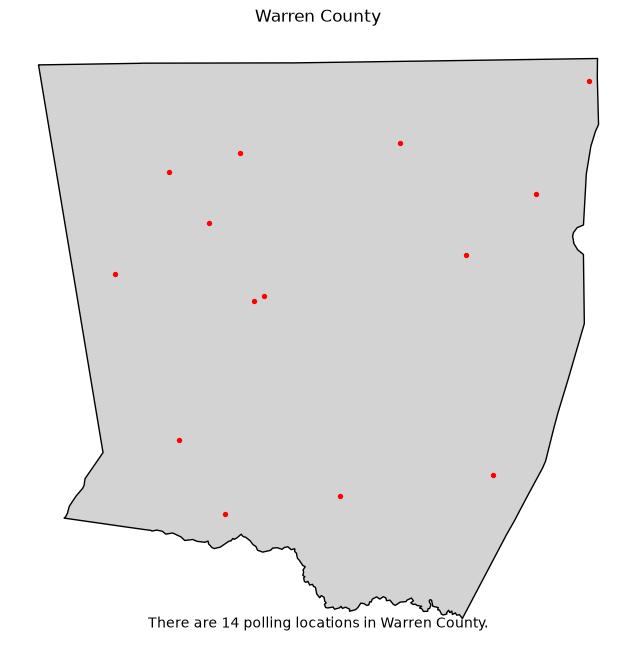

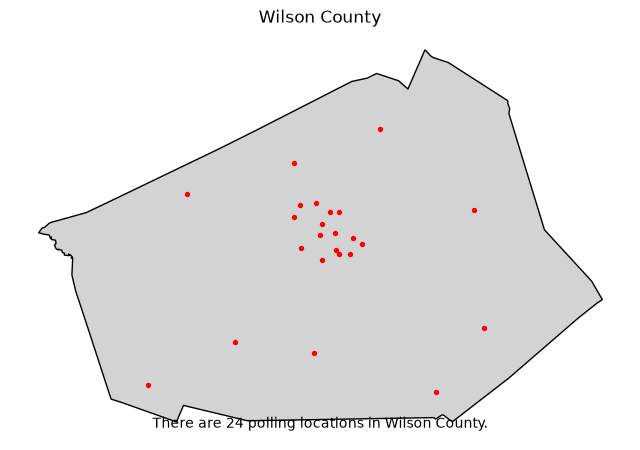

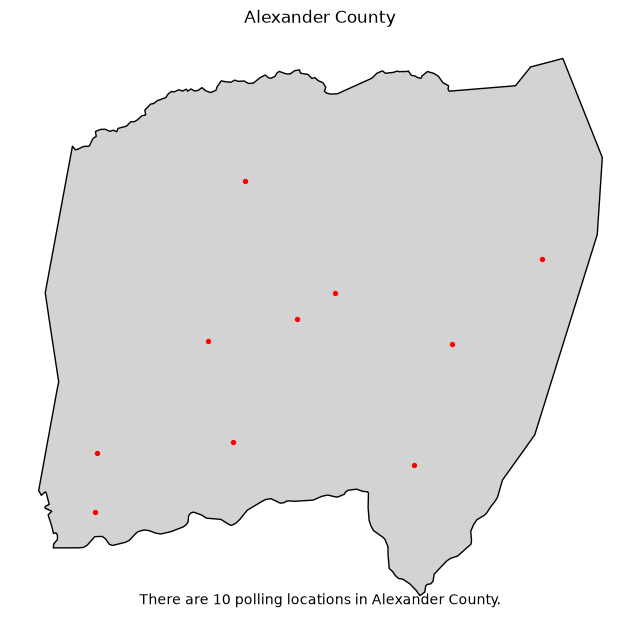

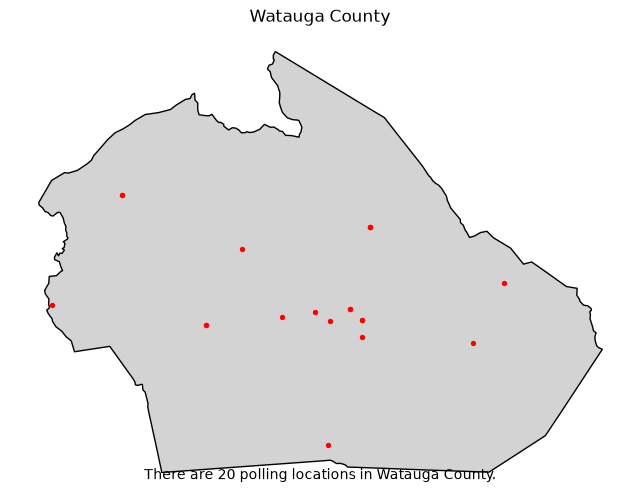

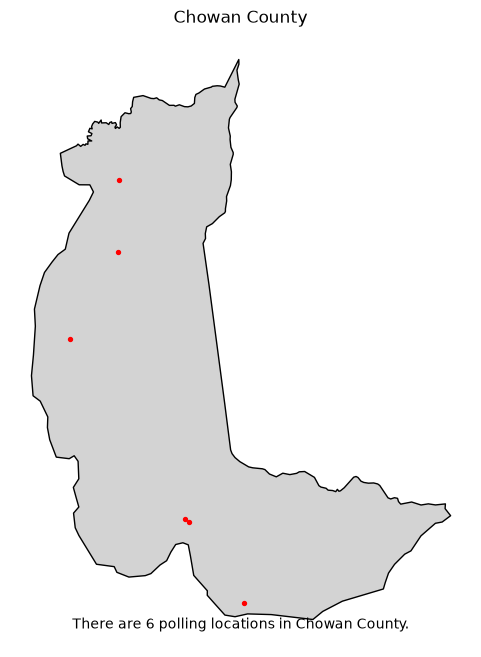

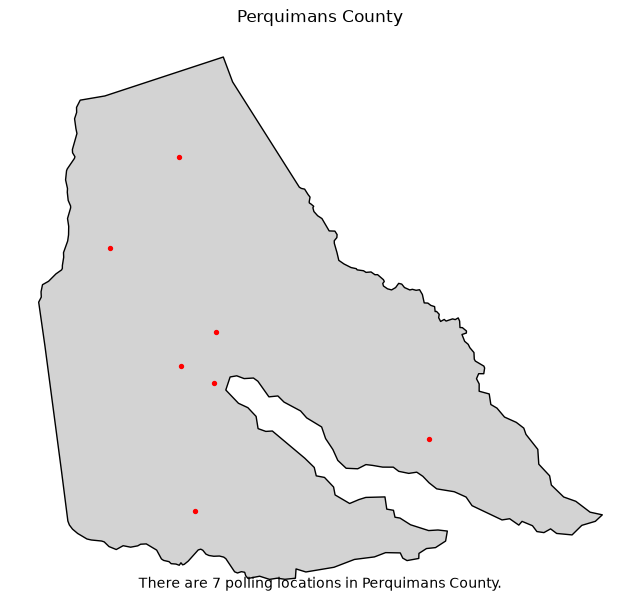

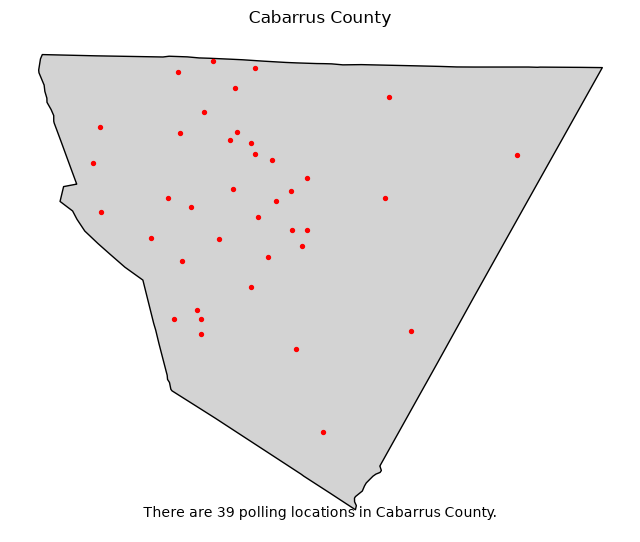

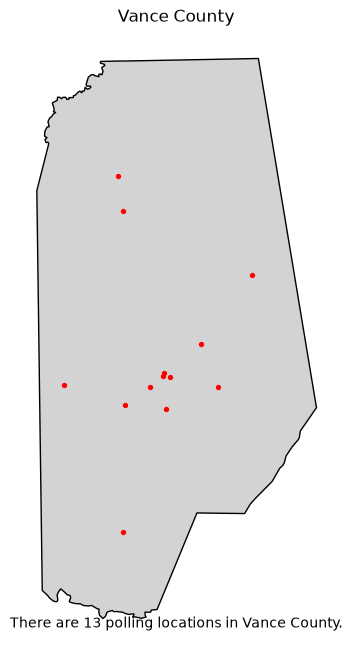

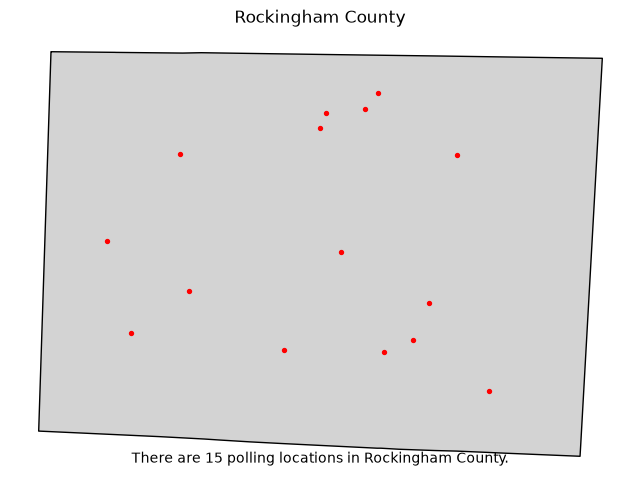

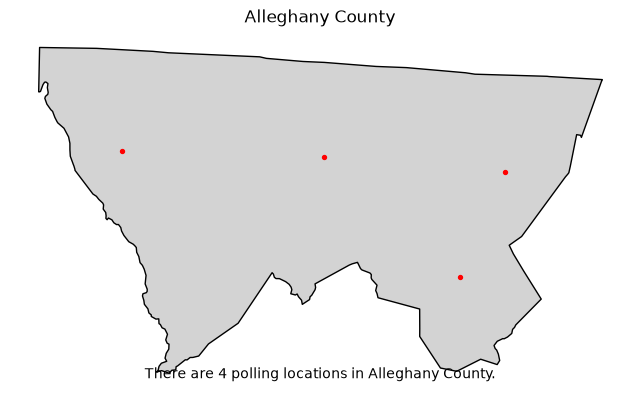

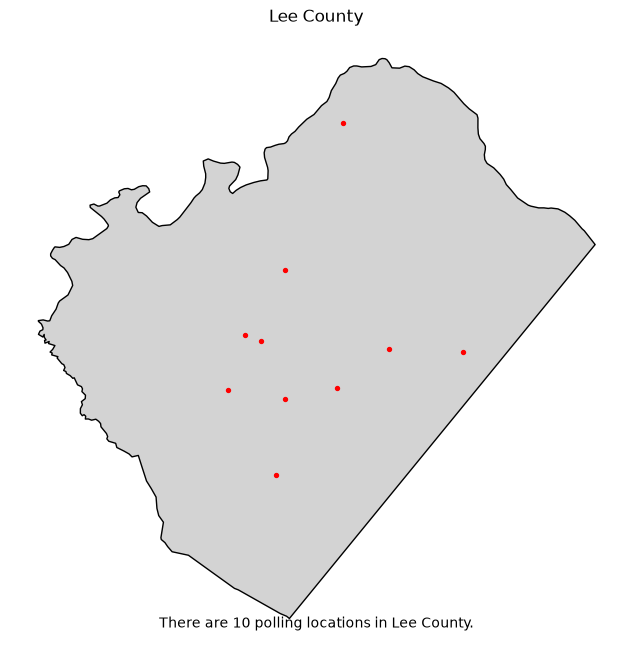

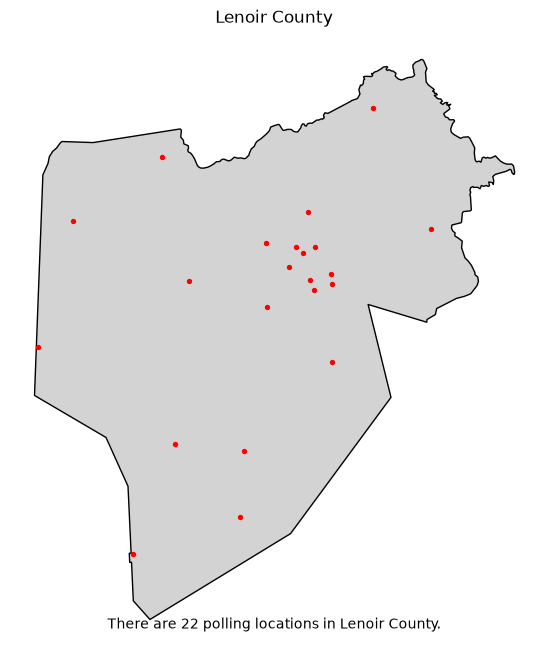

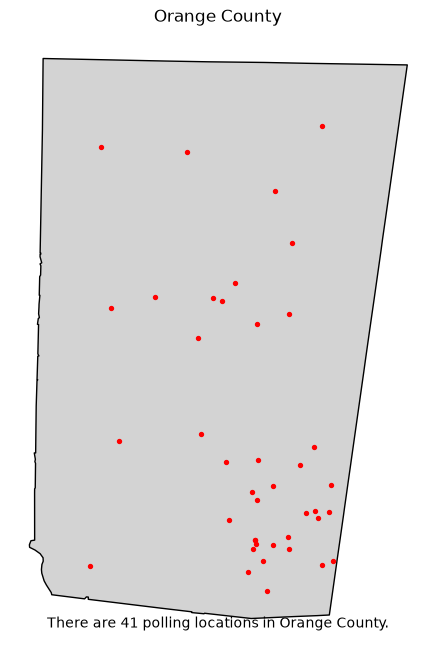

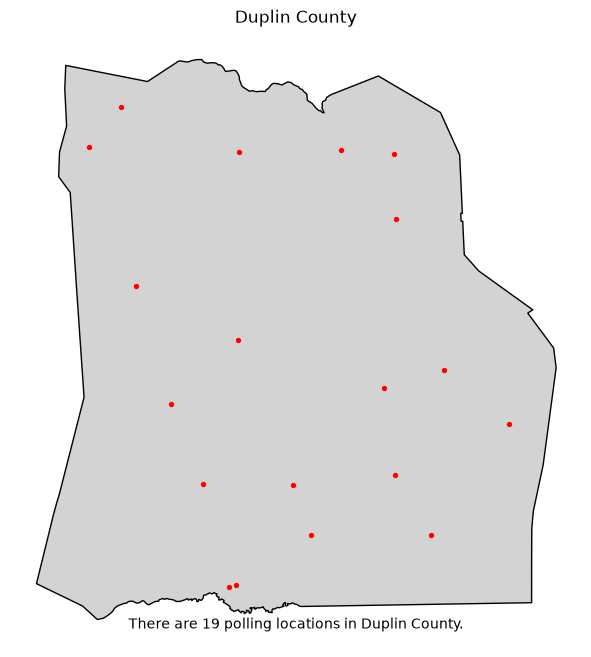

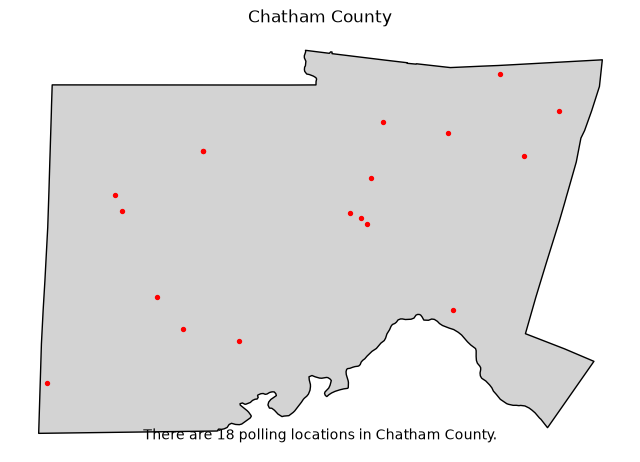

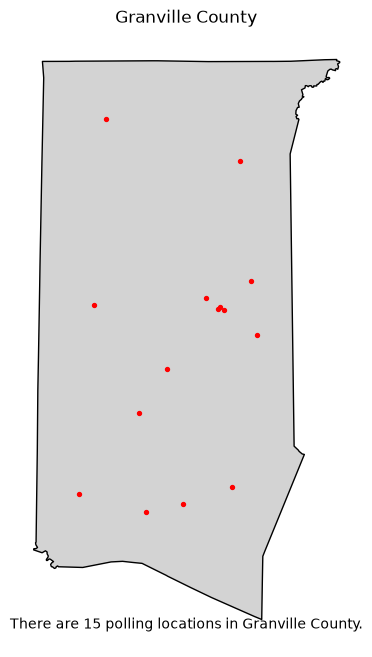

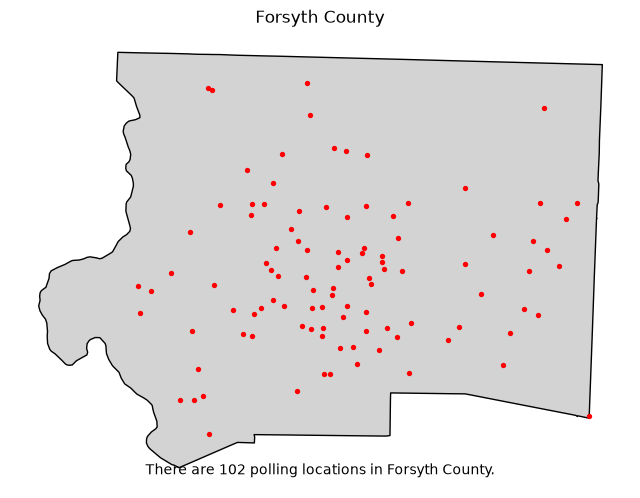

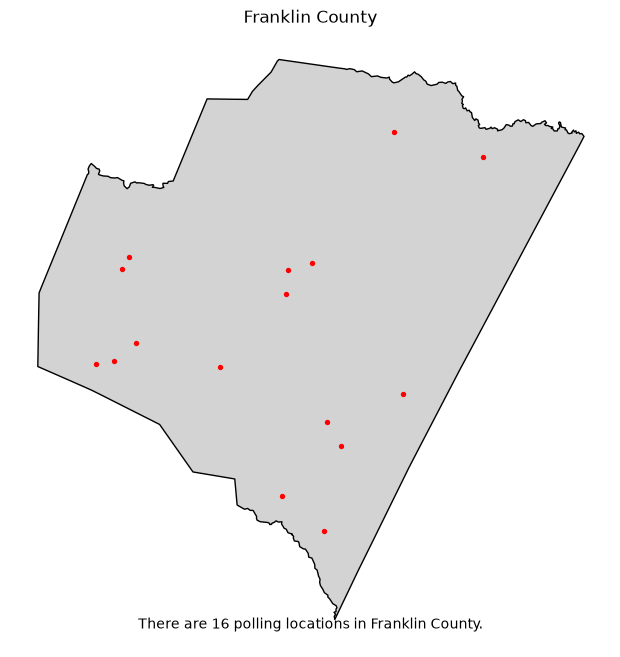

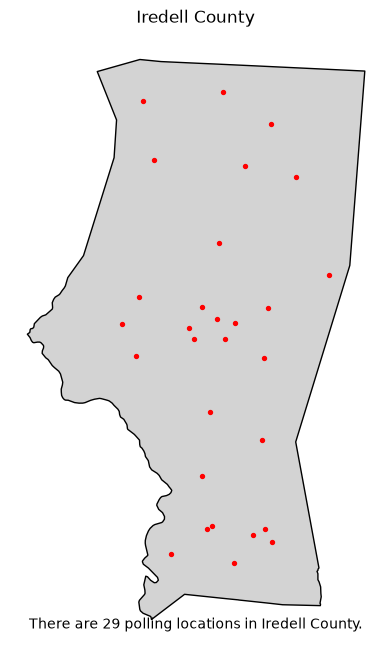

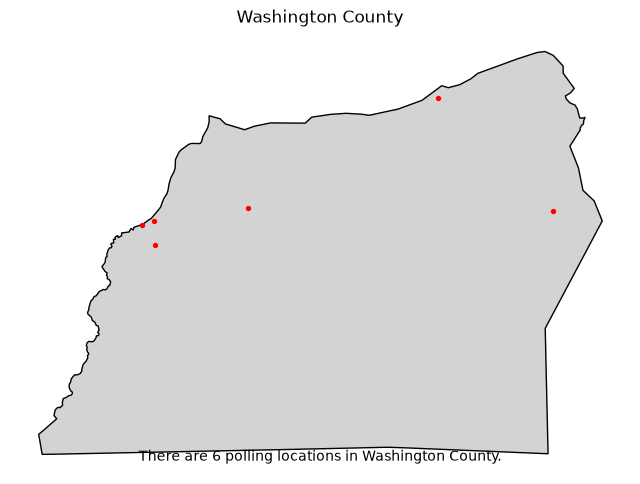

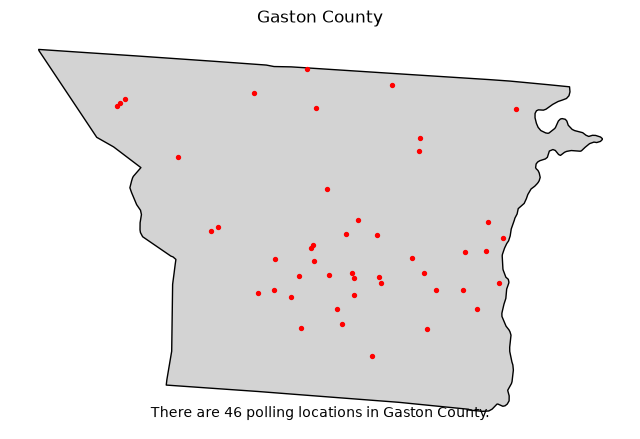

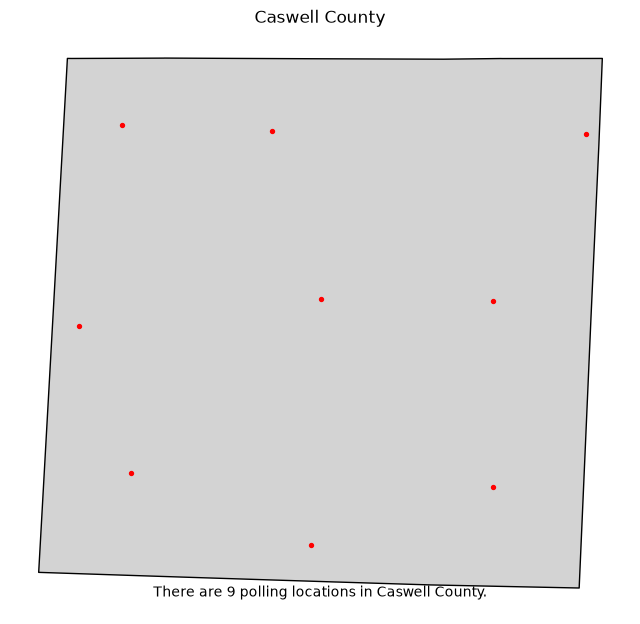

In [ ]:
counts = polls_nc.groupby("index_right").size()

for index, county in nc_counties.iterrows():

    count = counts.get(index, 0)

    message = (
        "There are " + str(count) +
        " polling locations in " + county["NAME"] +
        " County."
    )

    fig, ax = plt.subplots(figsize=(8, 8))

    gpd.GeoDataFrame(
        [county], crs=nc_counties.crs
    ).plot(ax=ax, color="lightgray", edgecolor="black")

    polls_nc.loc[polls_nc["index_right"] == index].plot(
        ax=ax, color="red", markersize=8
    )

    ax.set_title(county["NAME"] + " County")
    ax.text(
        0.5, 0.03, message,
        transform=ax.transAxes,
        ha="center"
    )
    ax.set_axis_off()

    plt.show()